In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import nbimporter
from loading_and_inspection import breast_cancer_dataset

X, y = breast_cancer_dataset()

print("X shape:", X.shape)
print("X columns:", X.columns.tolist())

print("y shape:", y.shape)
print("y columns:", y.columns.tolist())

X shape: (569, 30)
X columns: ['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']
y shape: (569, 1)
y columns: ['Diagnosis']


In [3]:
import pandas as pd

df = pd.concat([X, y], axis=1)

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

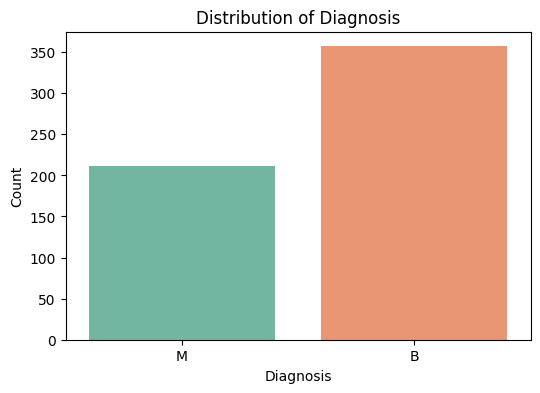

In [5]:
# Target distribution plot

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Diagnosis", hue="Diagnosis", 
              palette="Set2", legend=False)

plt.title("Distribution of Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

In [6]:
# Percentage Target distribution
print(
    df["Diagnosis"]
    .value_counts(normalize=True)
    .mul(100)
)

Diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


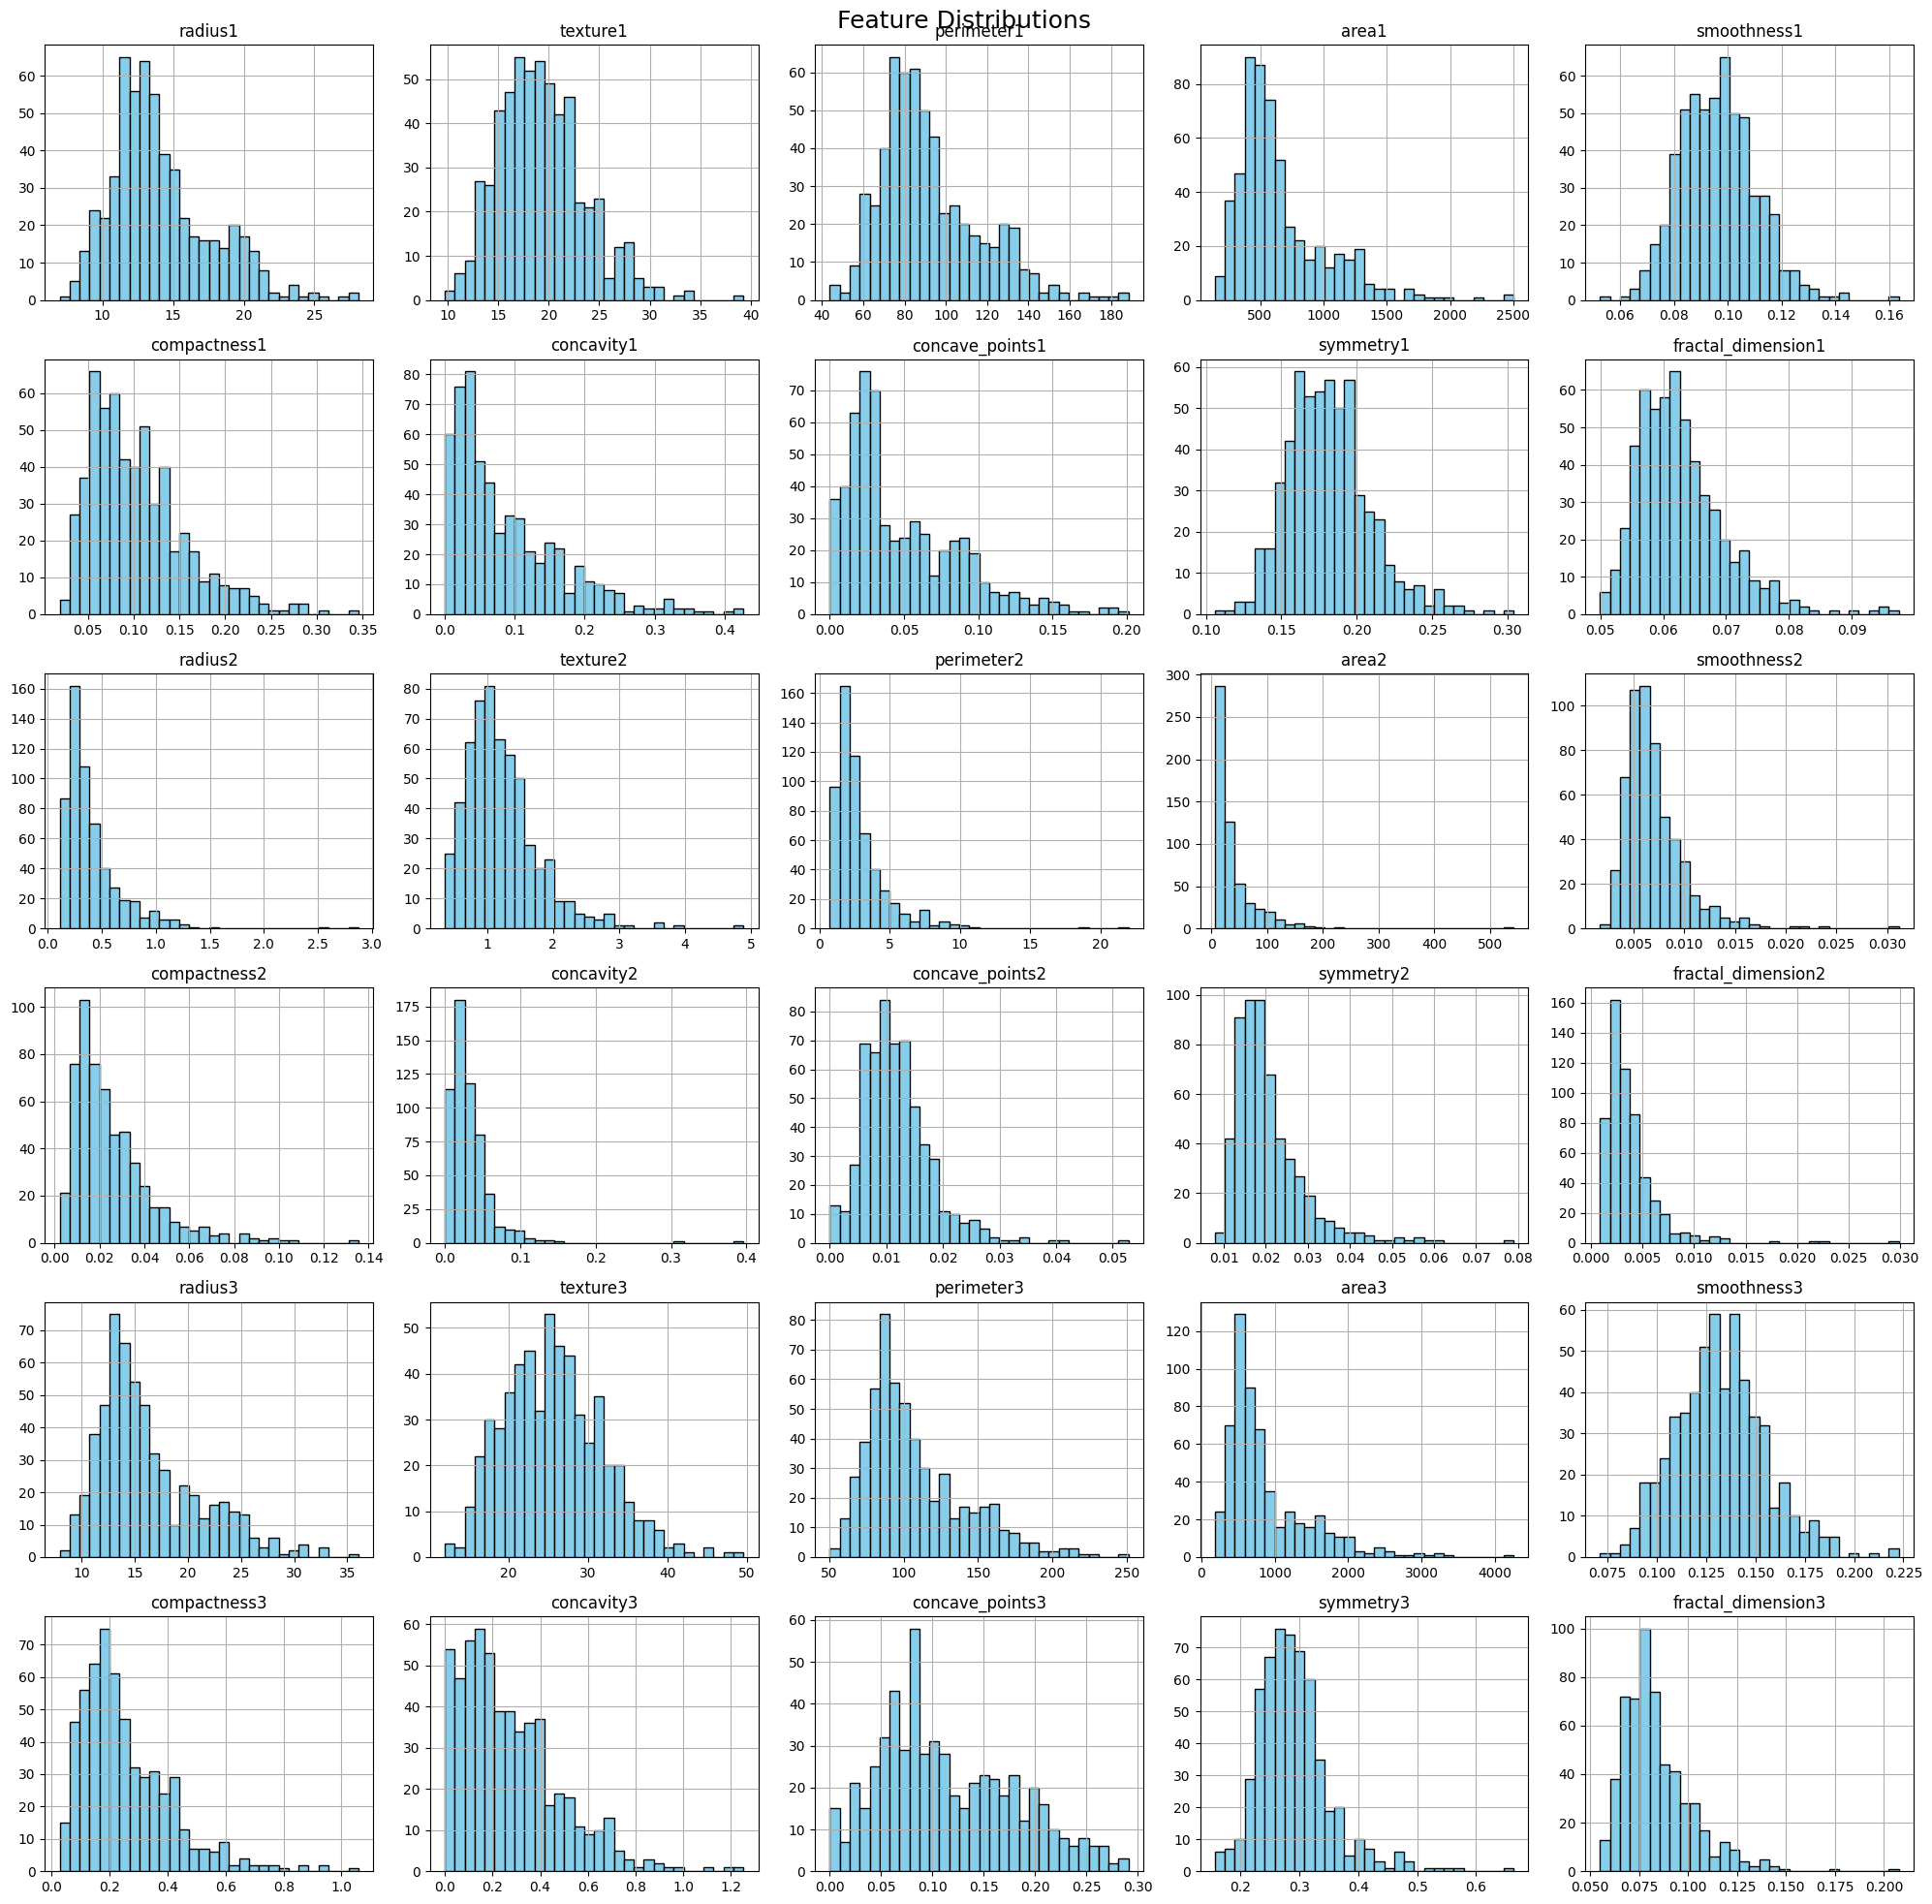

In [7]:
# Feature Distributions Histogram Plot

df.hist(figsize=(20, 20), bins=30, 
        color="skyblue", edgecolor="black")

plt.suptitle("Feature Distributions", fontsize=18)
plt.tight_layout()
plt.show()

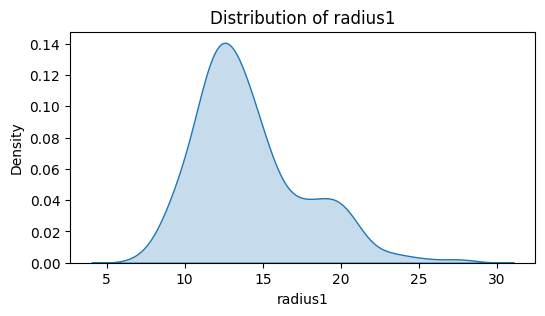

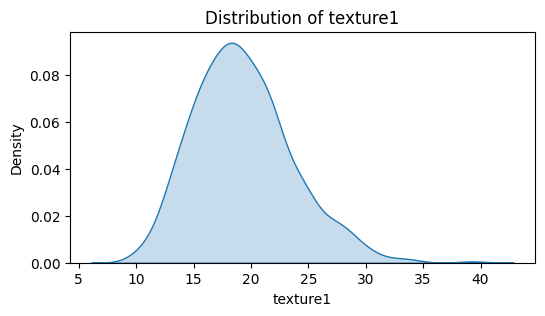

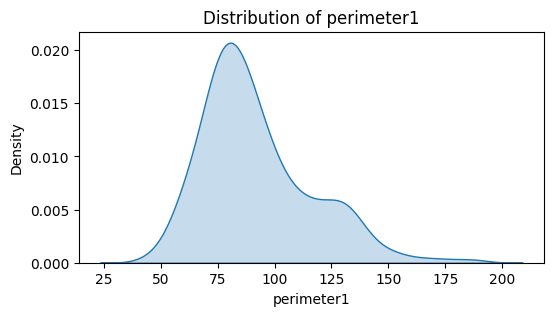

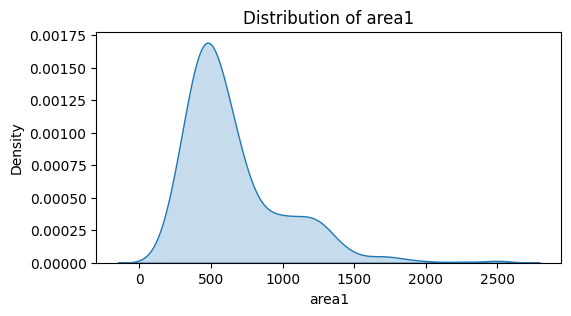

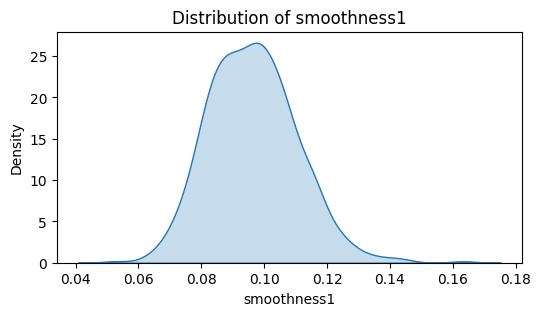

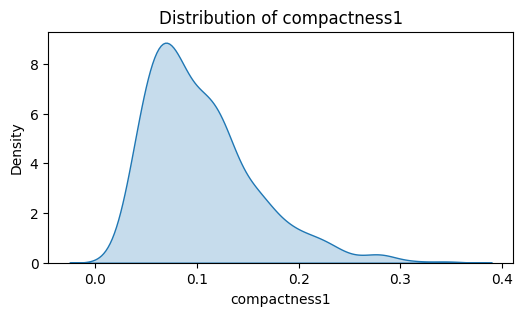

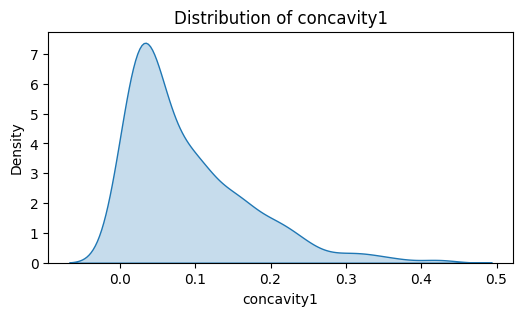

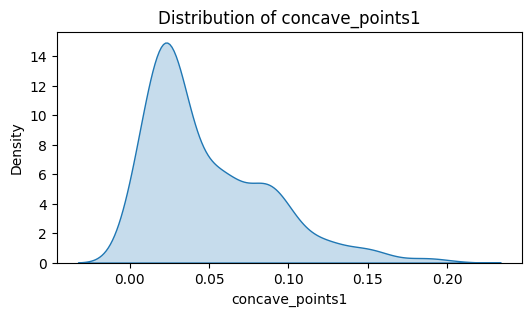

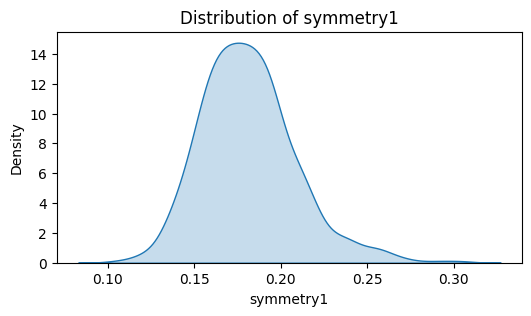

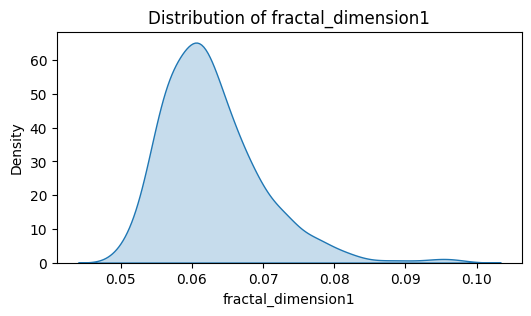

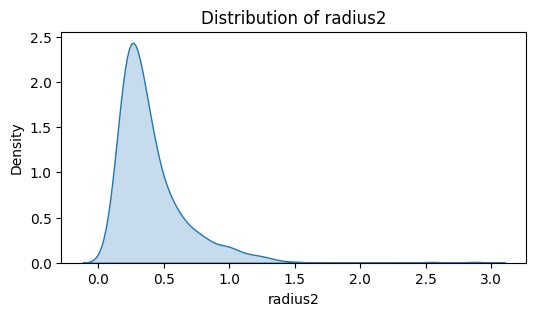

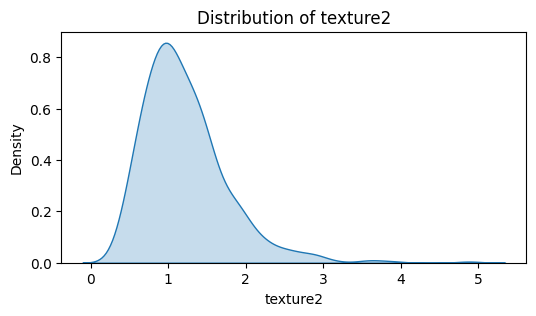

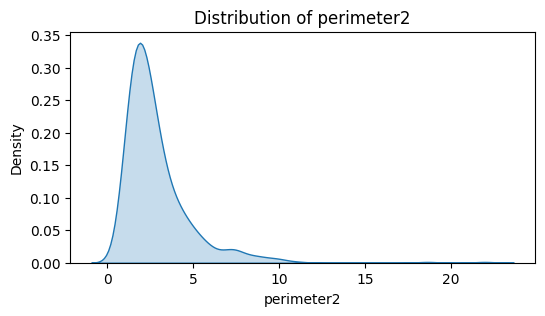

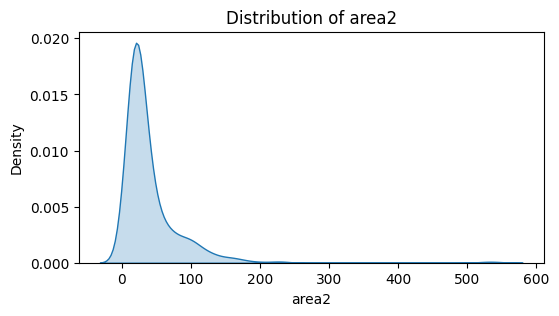

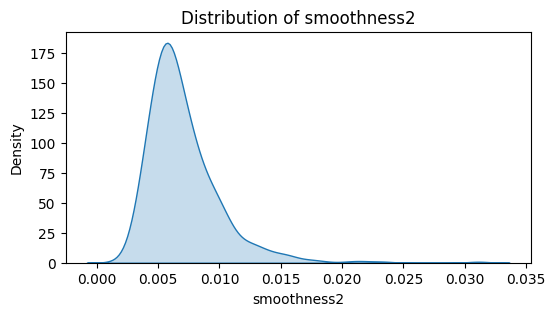

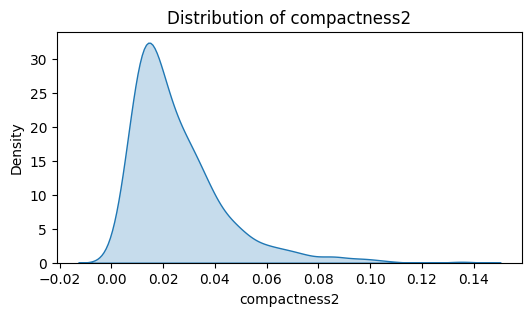

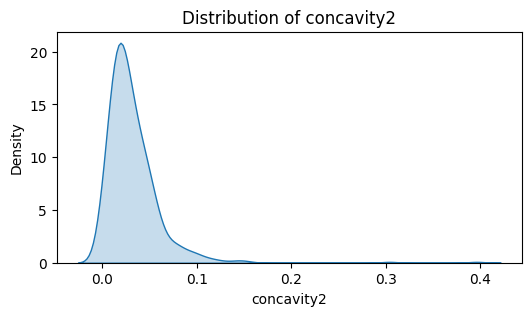

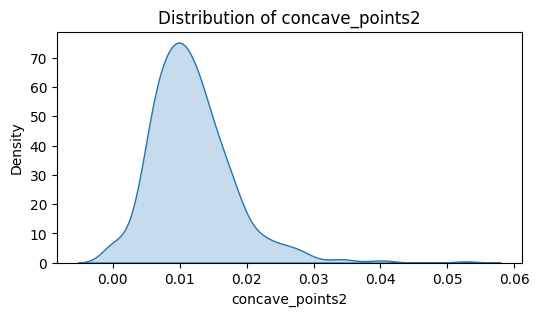

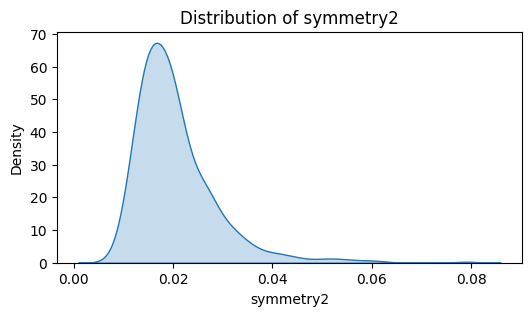

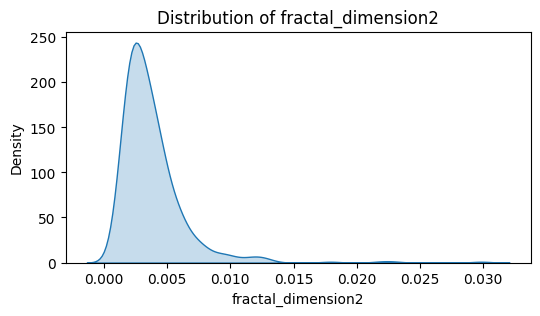

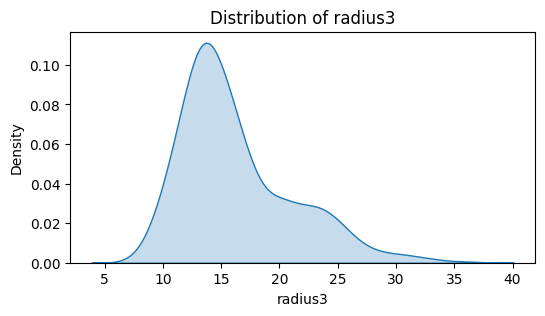

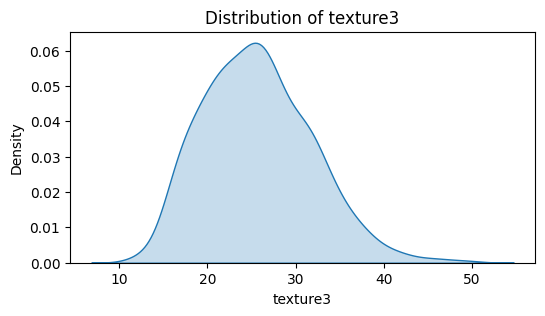

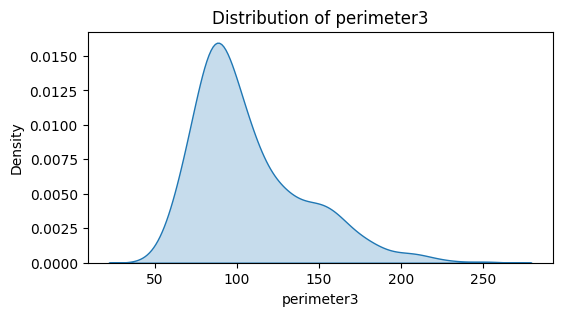

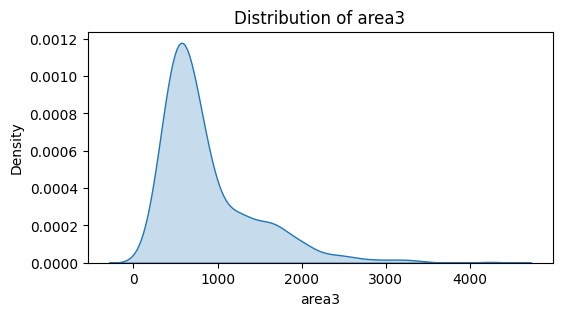

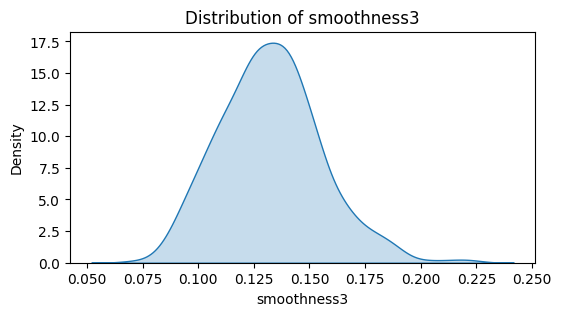

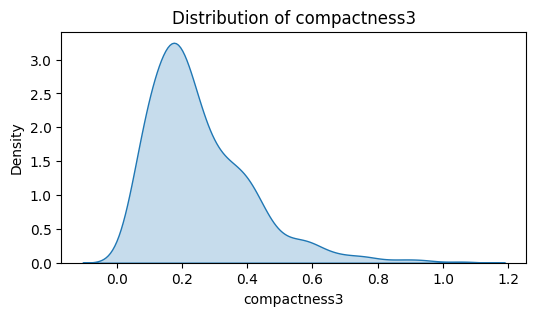

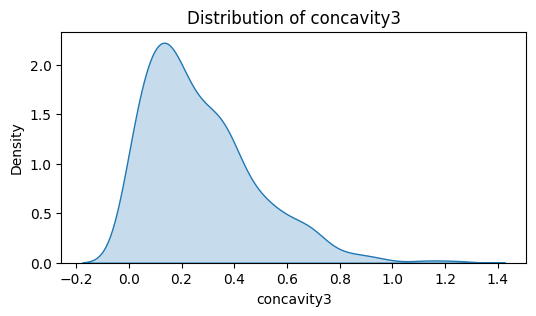

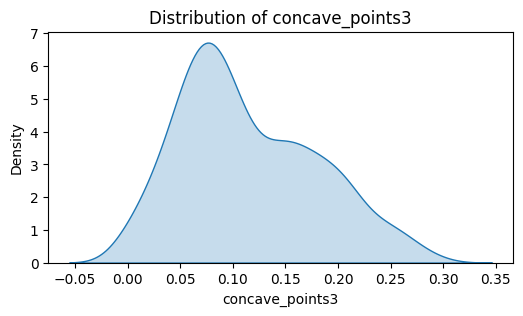

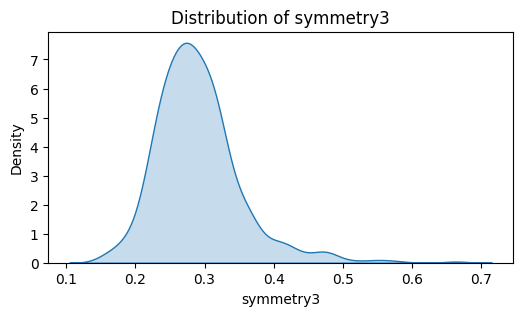

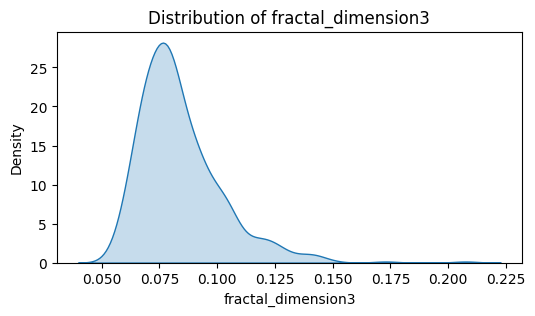

In [8]:
import numpy as np

# Feature Distribution using KDE plots

features = df.select_dtypes(include=np.number).columns

for col in features:
    plt.figure(figsize=(6, 3))
    sns.kdeplot(data=df, x=col, fill=True)
    plt.title(f"Distribution of {col}")
    plt.show()

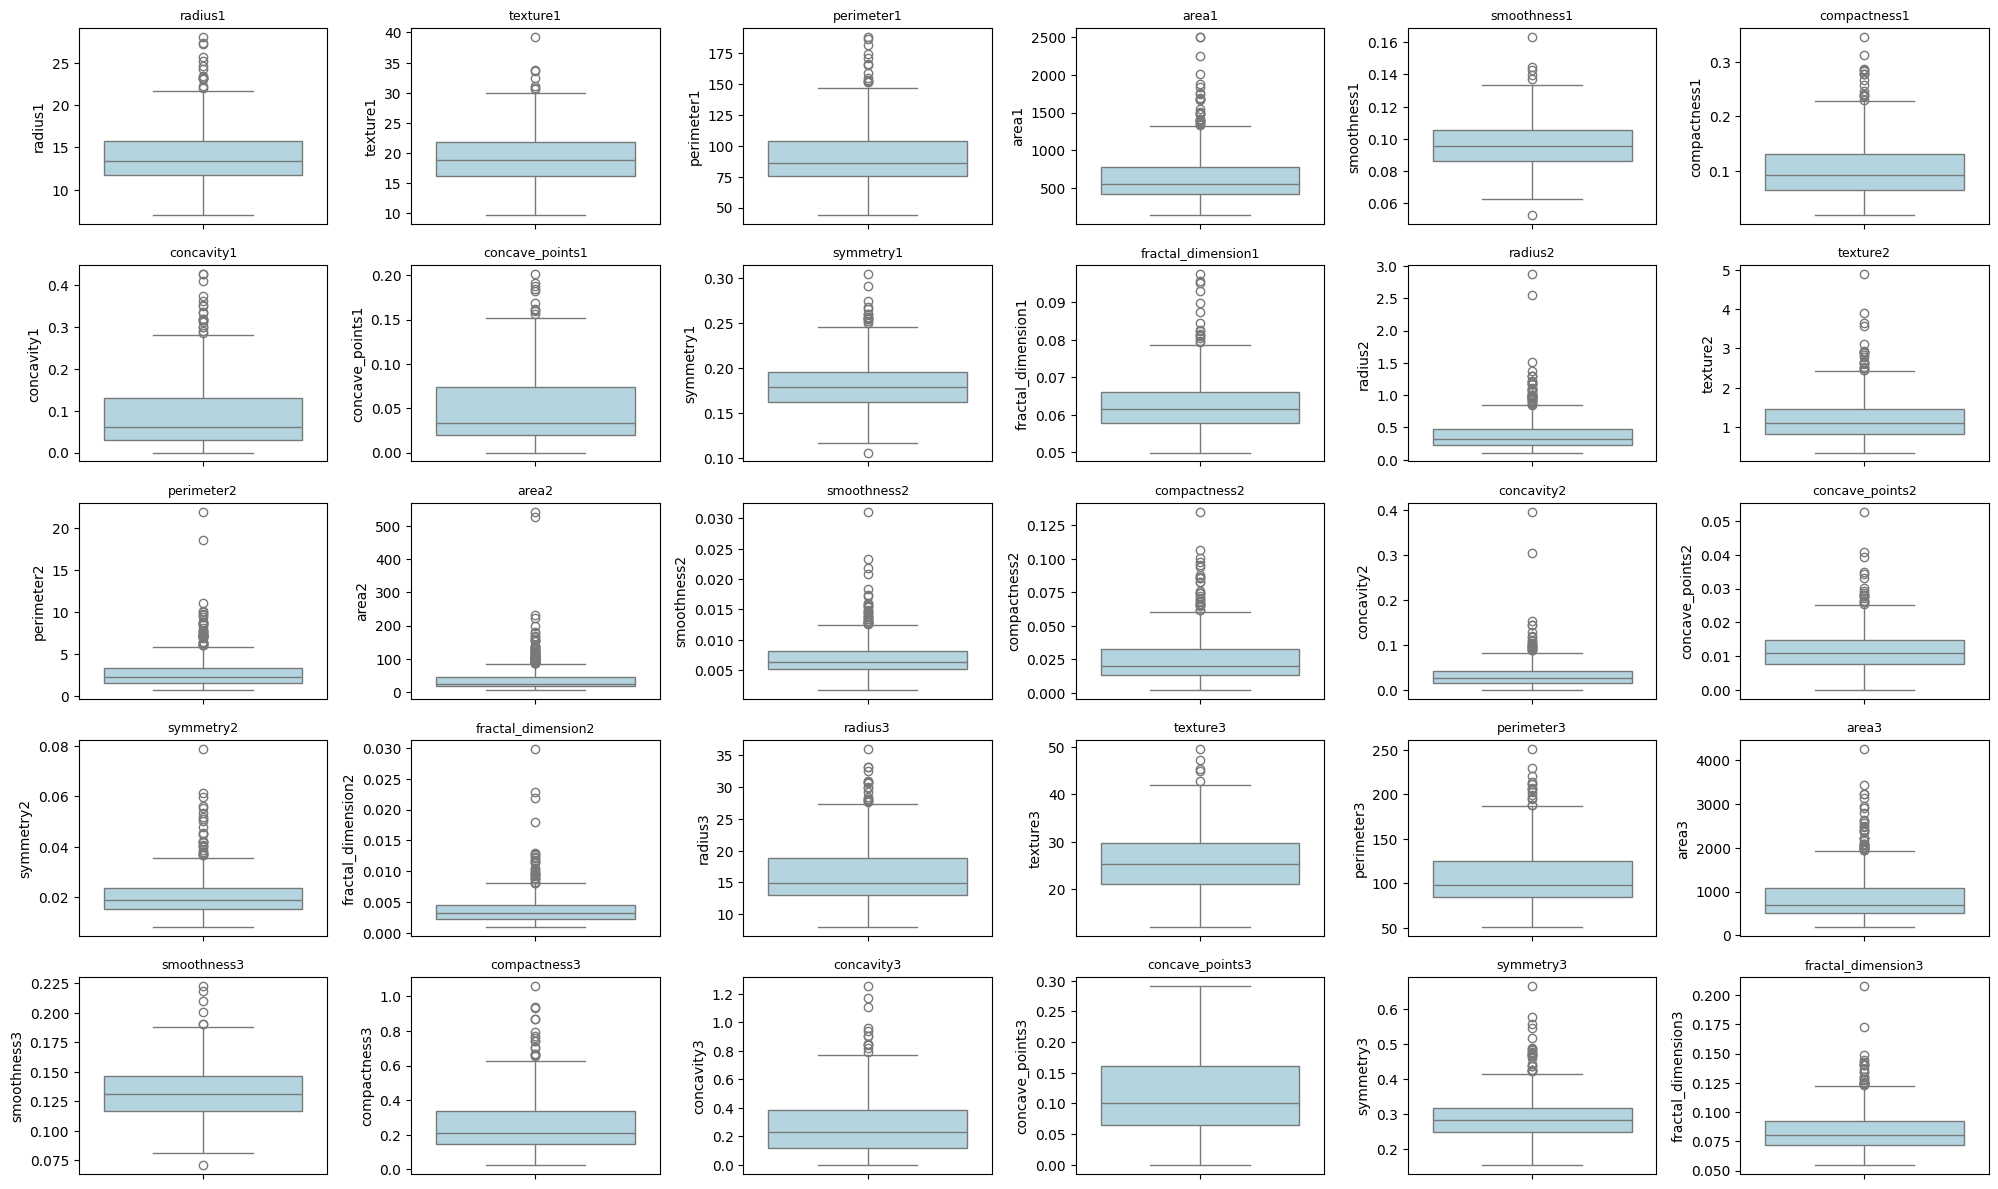

In [9]:
# Outlier detection - Boxplots

features = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(20, 12))

for i, col in enumerate(features, 1):
    plt.subplot(5, 6, i)
    sns.boxplot(y=df[col], color="lightblue")
    plt.title(col, fontsize=9)

plt.tight_layout()
plt.show()

In [10]:
# Outlier detection - IQR method

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")

radius1: 14 outliers
texture1: 7 outliers
perimeter1: 13 outliers
area1: 25 outliers
smoothness1: 6 outliers
compactness1: 16 outliers
concavity1: 18 outliers
concave_points1: 10 outliers
symmetry1: 15 outliers
fractal_dimension1: 15 outliers
radius2: 38 outliers
texture2: 20 outliers
perimeter2: 38 outliers
area2: 65 outliers
smoothness2: 30 outliers
compactness2: 28 outliers
concavity2: 22 outliers
concave_points2: 19 outliers
symmetry2: 27 outliers
fractal_dimension2: 28 outliers
radius3: 17 outliers
texture3: 5 outliers
perimeter3: 15 outliers
area3: 35 outliers
smoothness3: 7 outliers
compactness3: 16 outliers
concavity3: 12 outliers
concave_points3: 0 outliers
symmetry3: 23 outliers
fractal_dimension3: 24 outliers


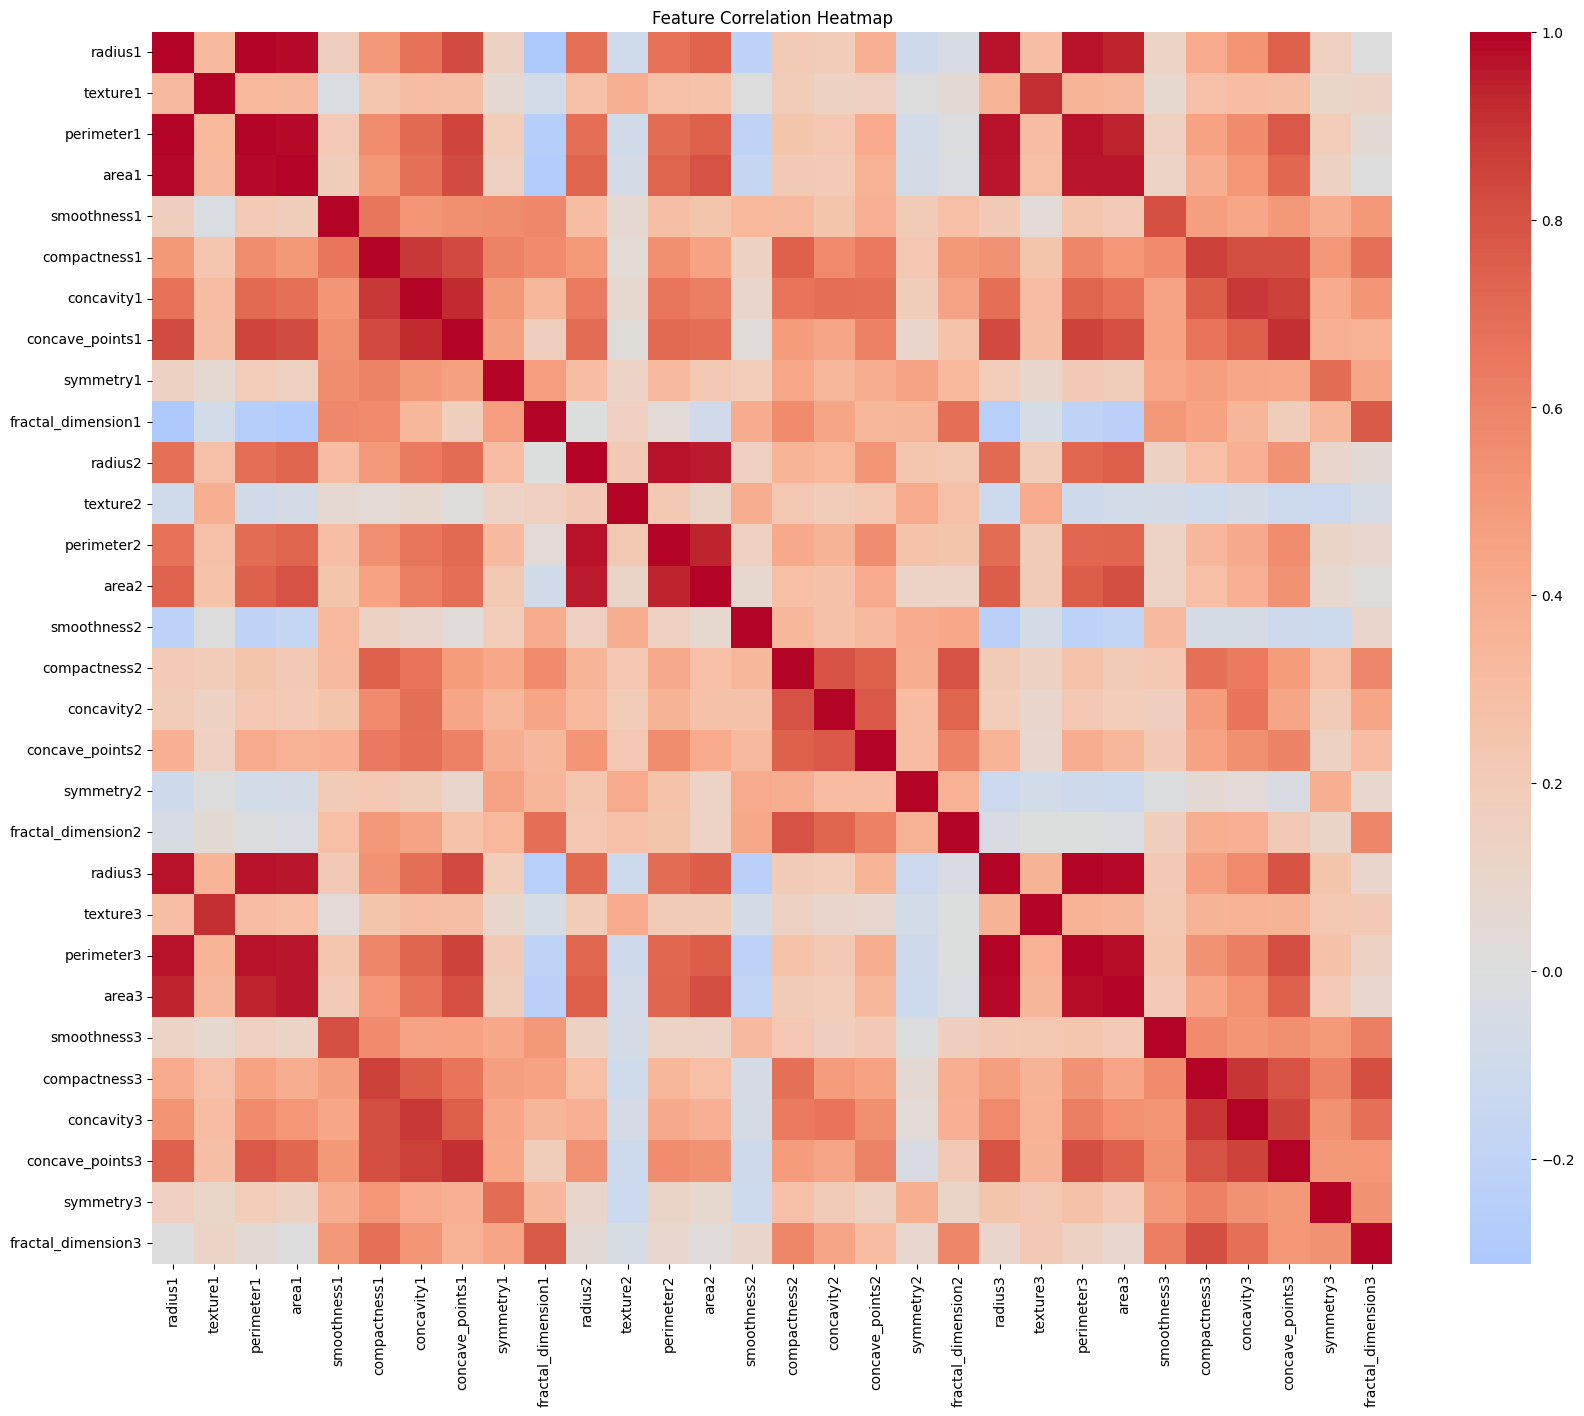

In [11]:
# Correlation matrix

corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(20, 16))

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=False,
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [12]:
# Find highly correlated features

corr_matrix = df.select_dtypes(include=np.number).corr()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

display(
    high_corr[
        high_corr["Correlation"].abs() > 0.85
    ].sort_values(by="Correlation", key=abs, ascending=False)
)

,Feature 1,Feature 2,Correlation
1,radius1,perimeter1,0.997855
391,radius3,perimeter3,0.993708
2,radius1,area1,0.987357
57,perimeter1,area1,0.986507
392,radius3,area3,0.984015
407,perimeter3,area3,0.977578
246,radius2,perimeter2,0.972794
76,perimeter1,perimeter3,0.970387
19,radius1,radius3,0.969539
74,perimeter1,radius3,0.969476


In [13]:
# Class-wise feature comparison - Compare feature means
grouped = df.groupby("Diagnosis").mean().T

display(grouped)

Diagnosis,B,M
radius1,12.146524,17.462830
texture1,17.914762,21.604906
perimeter1,78.075406,115.365377
area1,462.790196,978.376415
smoothness1,0.092478,0.102898
compactness1,0.080085,0.145188
concavity1,0.046058,0.160775
concave_points1,0.025717,0.087990
symmetry1,0.174186,0.192909
fractal_dimension1,0.062867,0.062680


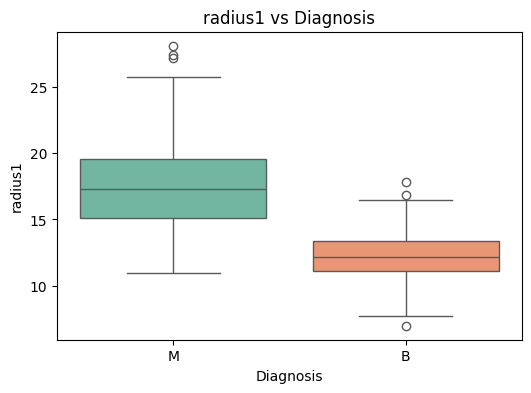

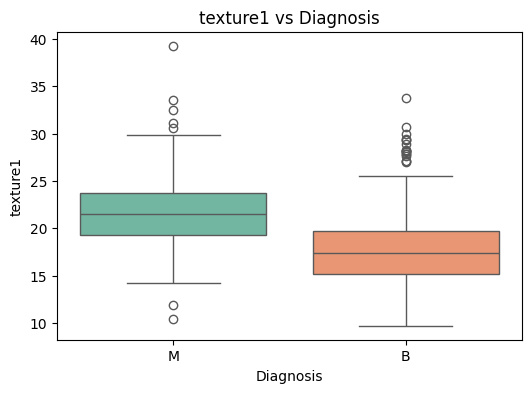

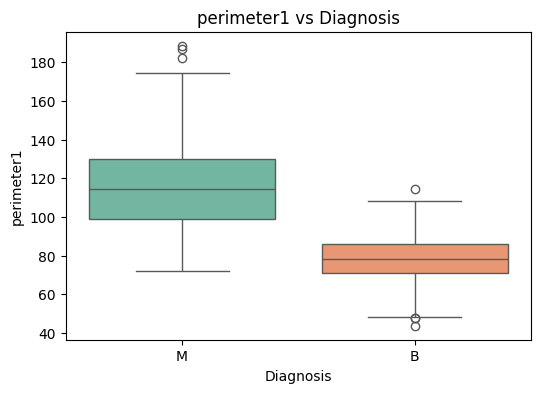

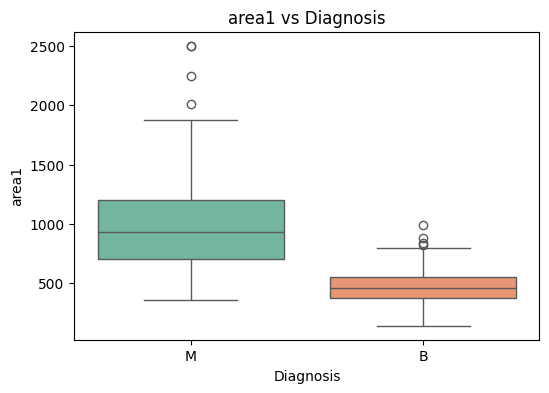

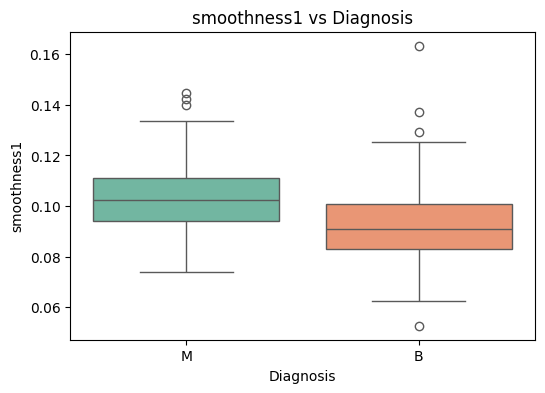

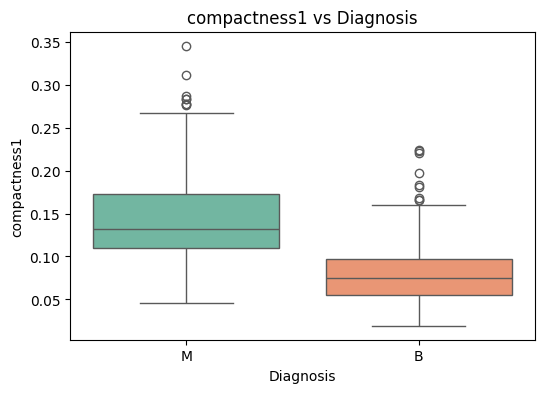

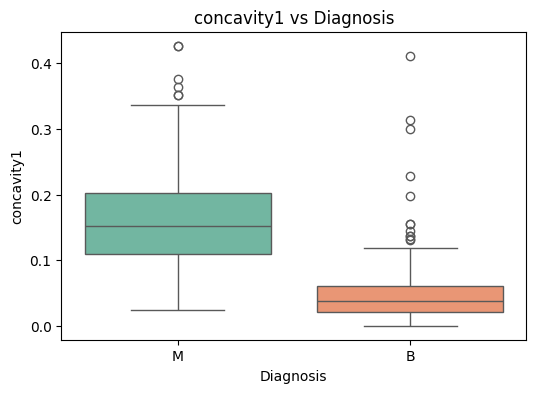

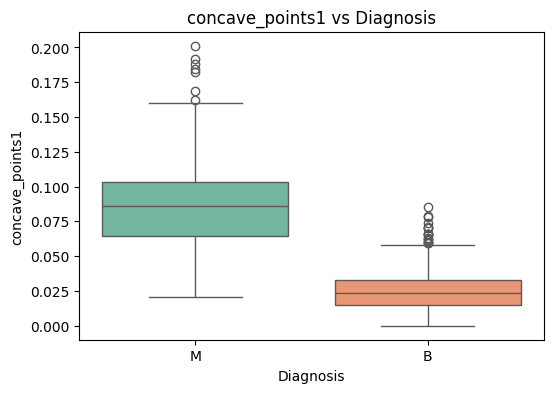

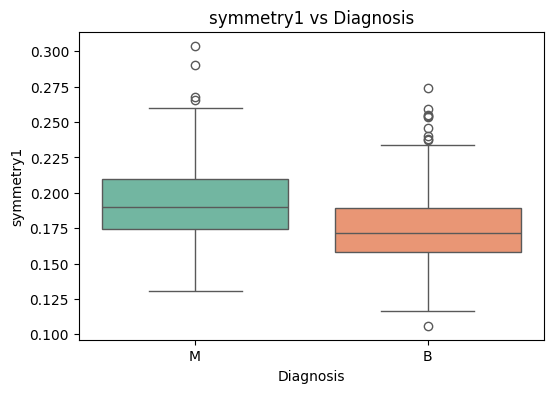

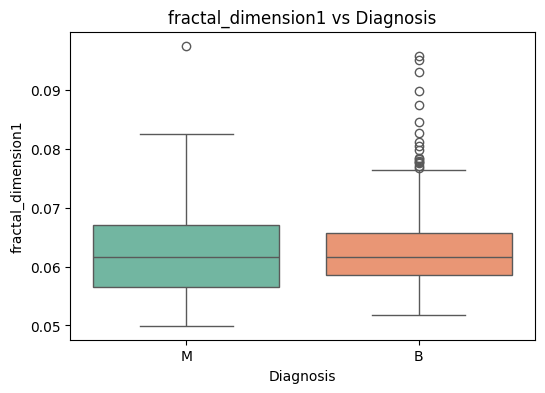

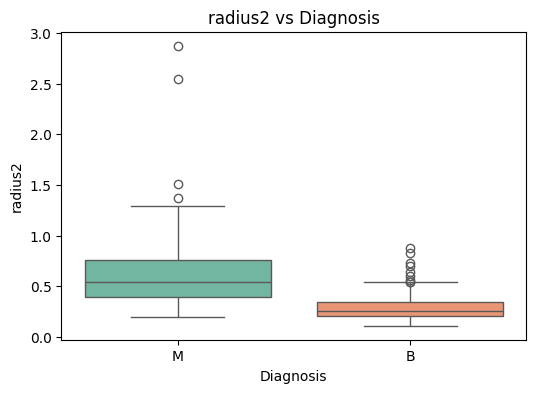

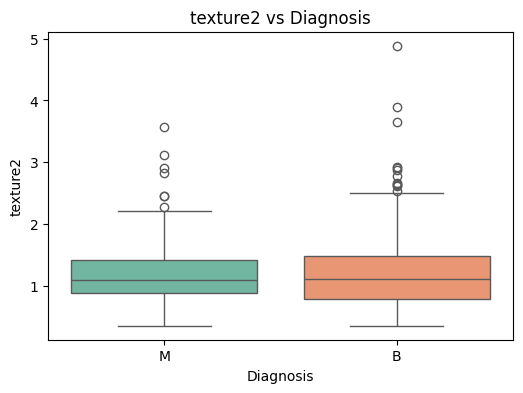

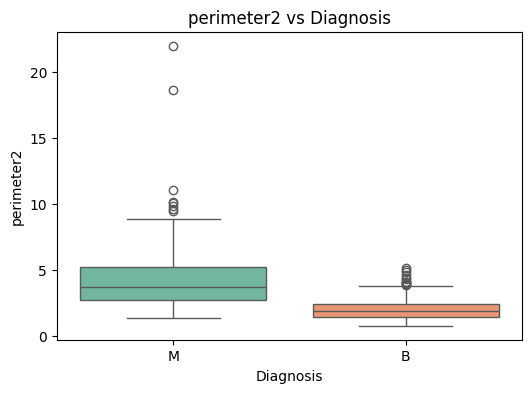

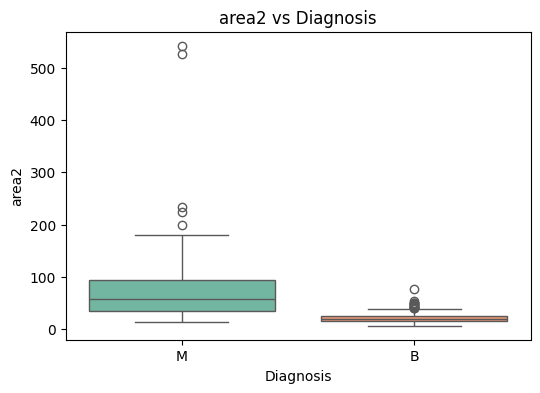

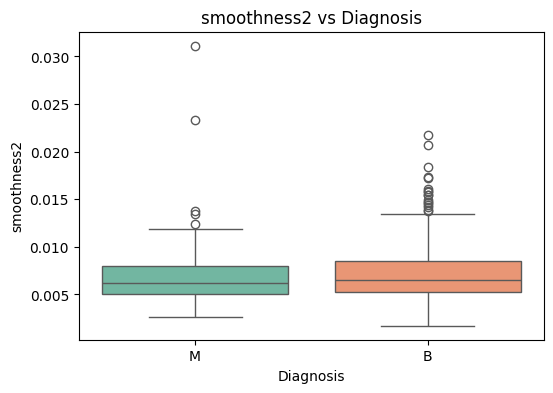

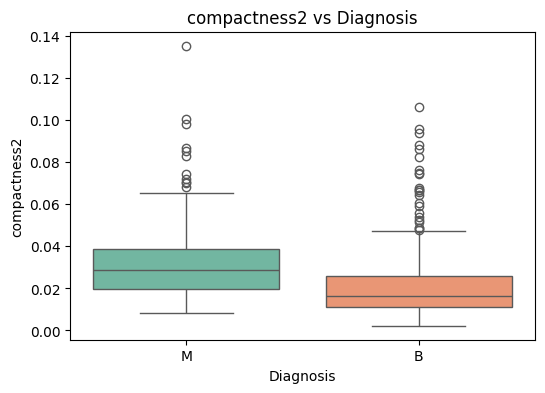

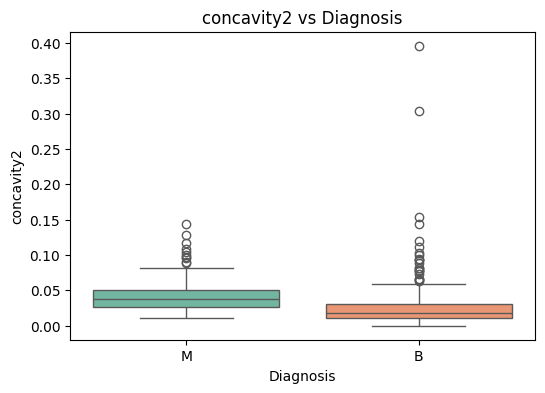

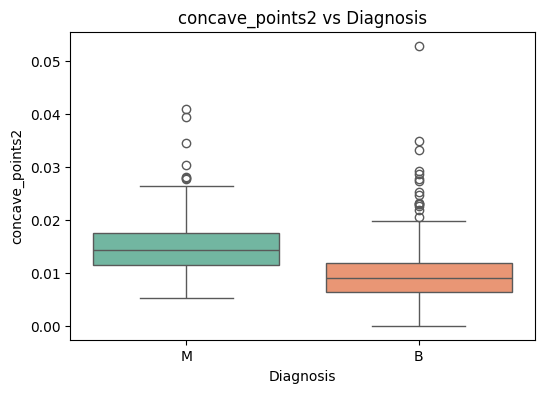

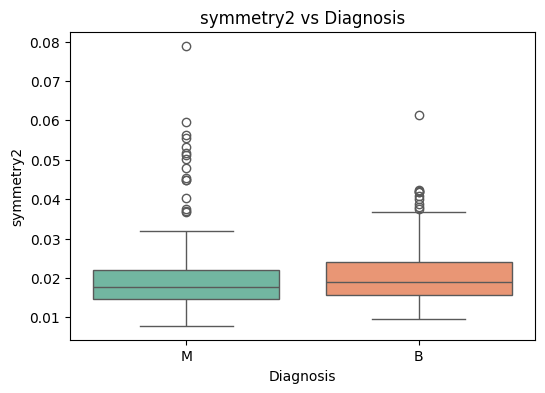

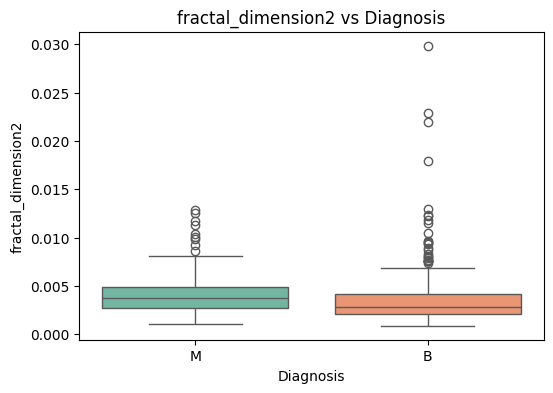

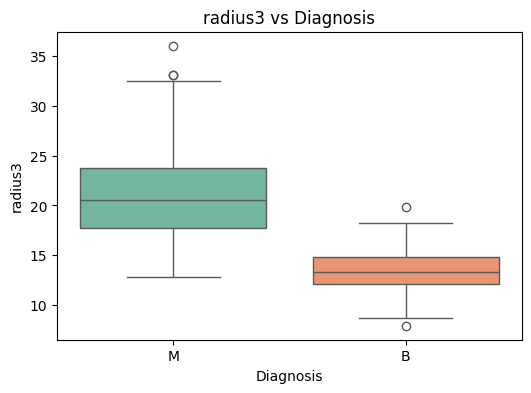

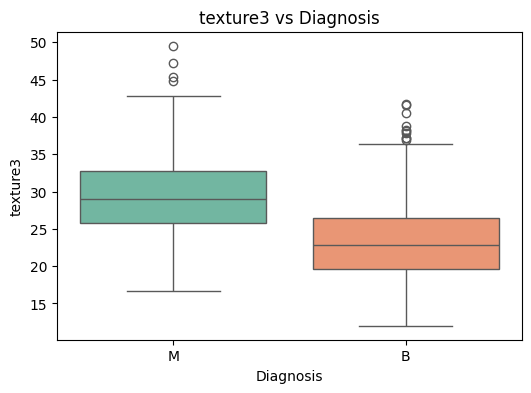

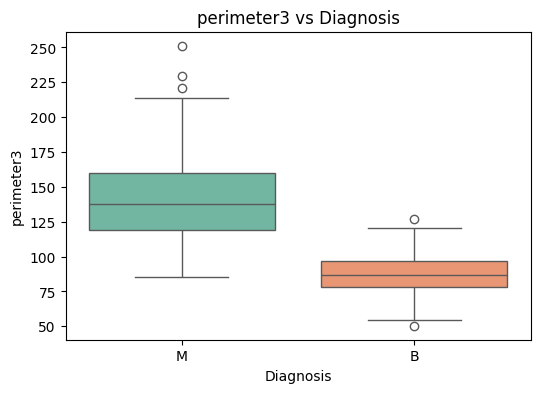

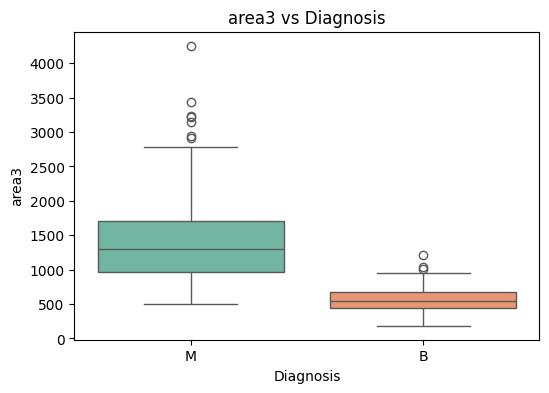

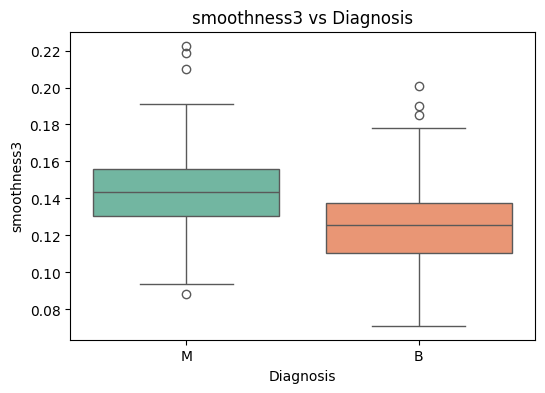

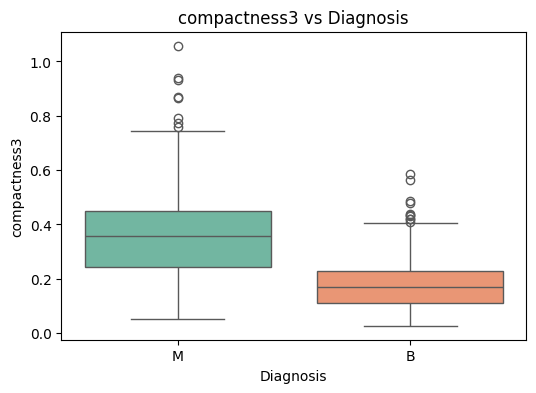

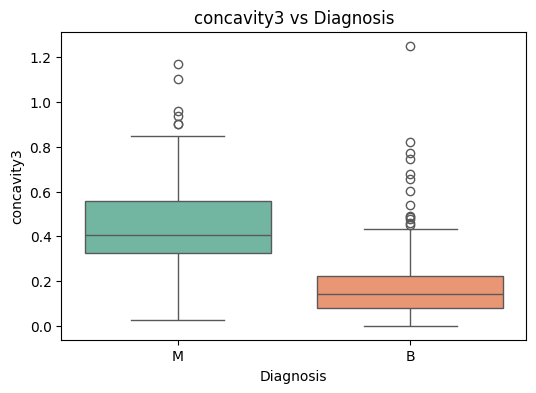

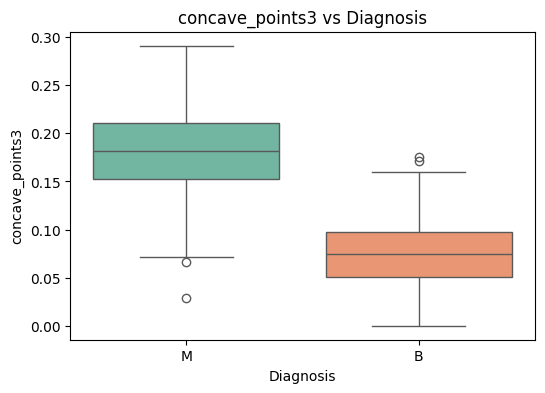

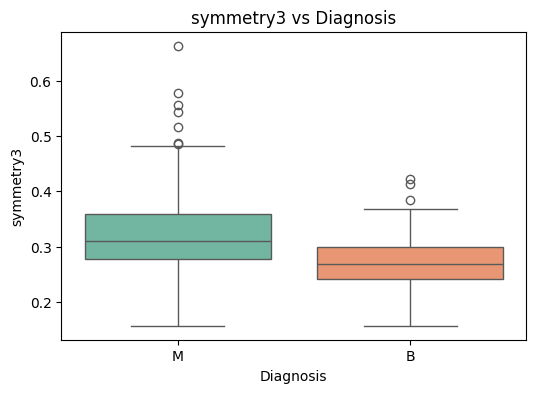

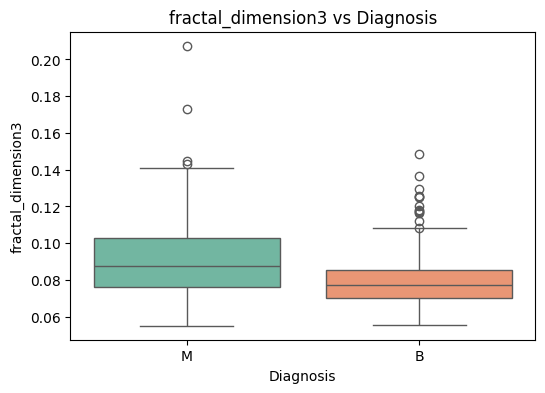

In [14]:
# Class-wise feature comparison - Visualize feature differences
for col in X.columns:
    plt.figure(figsize=(6, 4))

    sns.boxplot(
        data=df,
        x="Diagnosis",
        y=col,
        hue="Diagnosis",
        palette="Set2",
        legend=False
    )

    plt.title(f"{col} vs Diagnosis")
    plt.show()

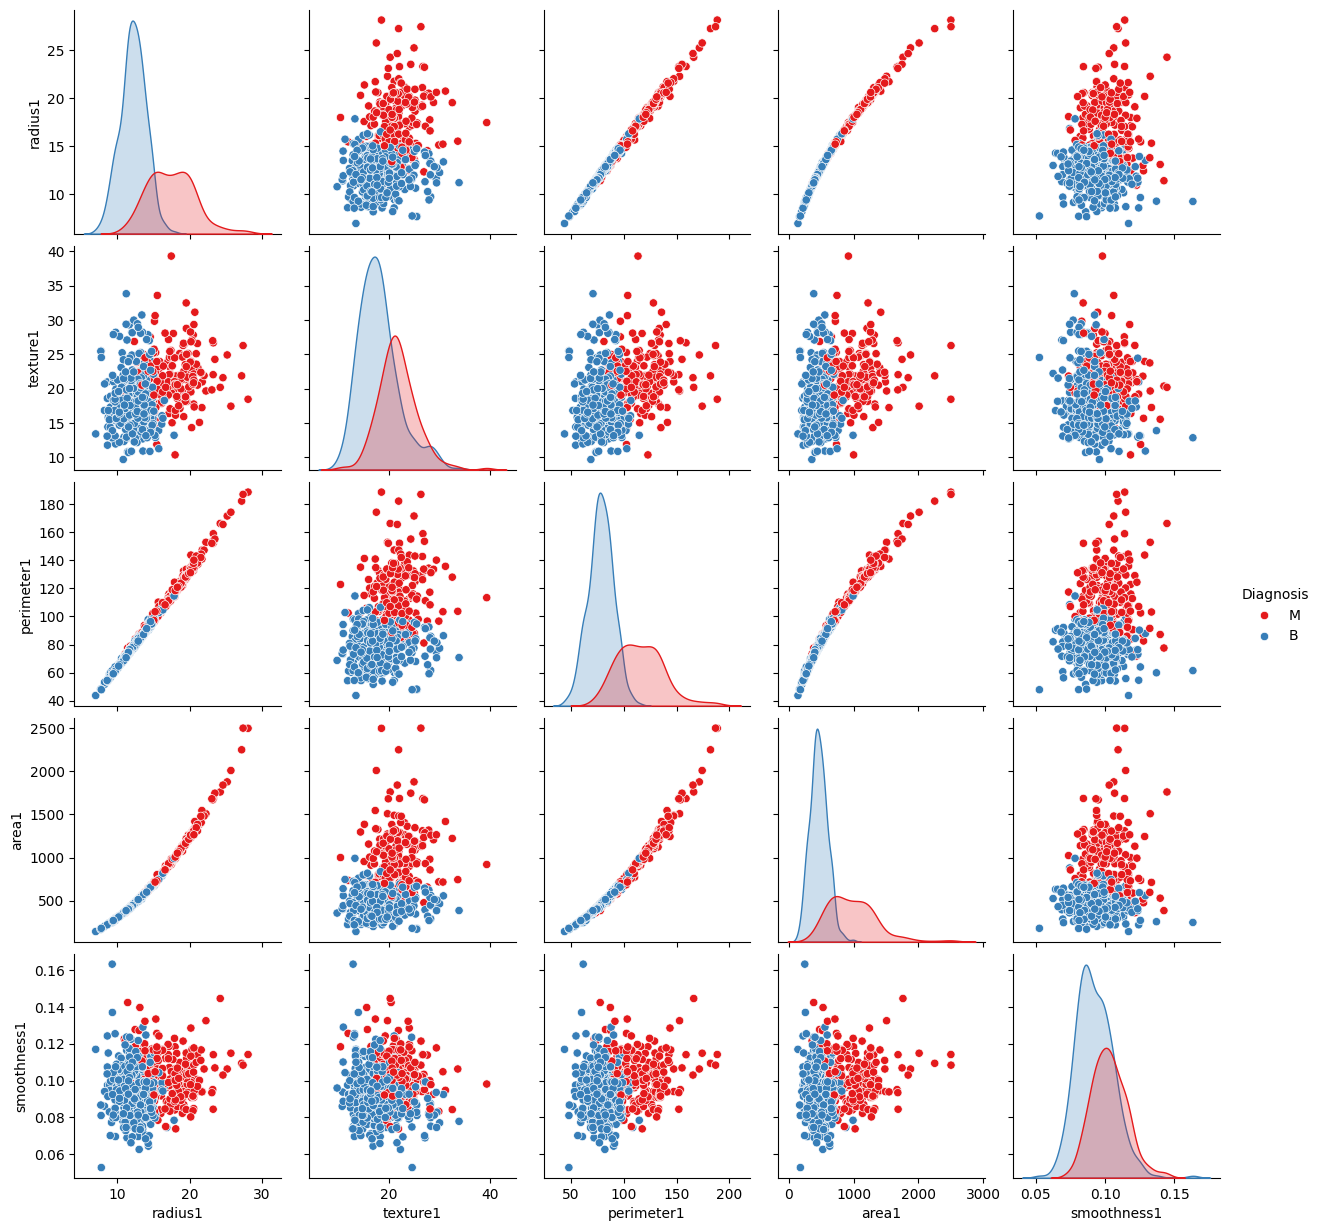

In [ ]:
# Pairplot for each measurement group
# all 30 features, this produces a 30 × 30 grid (900 subplots), which is computationally expensive and difficult to interpret.

# Your dataset has three measurement groups:

# Group 1: Mean measurements.
# Group 2: Standard error measurements.
# Group 3: Worst measurements.

# You can analyze each group separately.

# Group 1: Mean measurements
mean_features = [
    "radius1",
    "texture1",
    "perimeter1",
    "area1",
    "smoothness1",
    "Diagnosis"
]

sns.pairplot(
    df[mean_features],
    hue="Diagnosis",
    diag_kind="kde",
    palette="Set1"
)

plt.show()

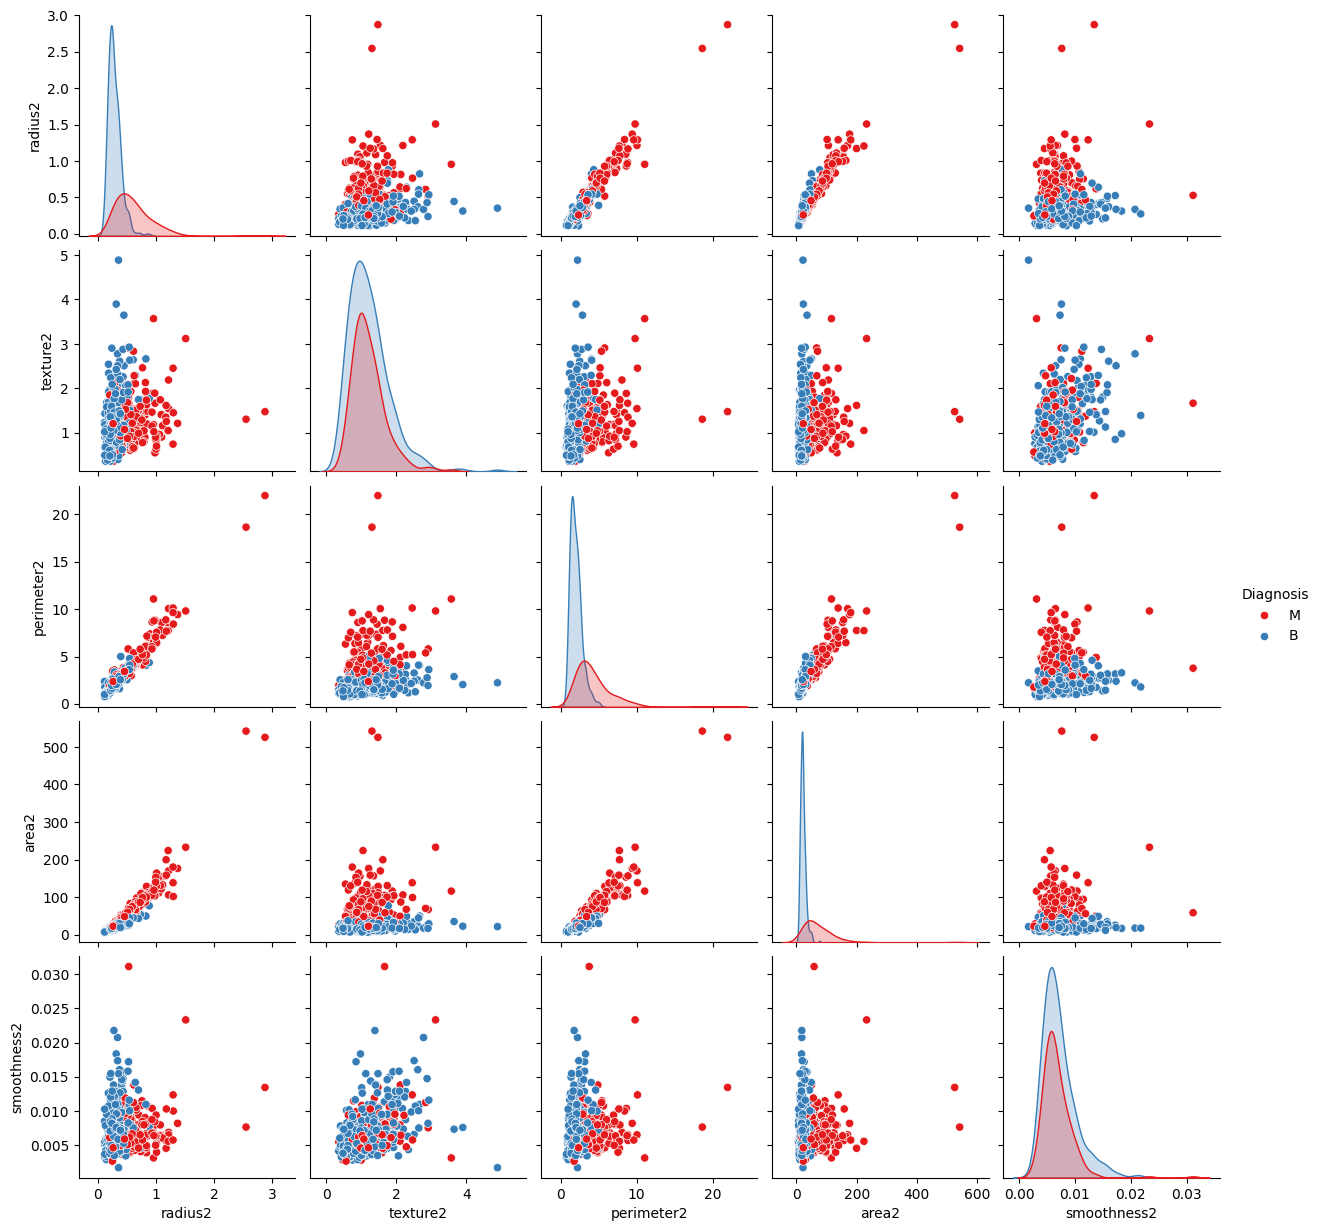

In [ ]:
# Group 2: Standard error measurements

se_features = [
    "radius2",
    "texture2",
    "perimeter2",
    "area2",
    "smoothness2",
    "Diagnosis"
]

sns.pairplot(
    df[se_features],
    hue="Diagnosis",
    diag_kind="kde",
    palette="Set1"
)

plt.show()

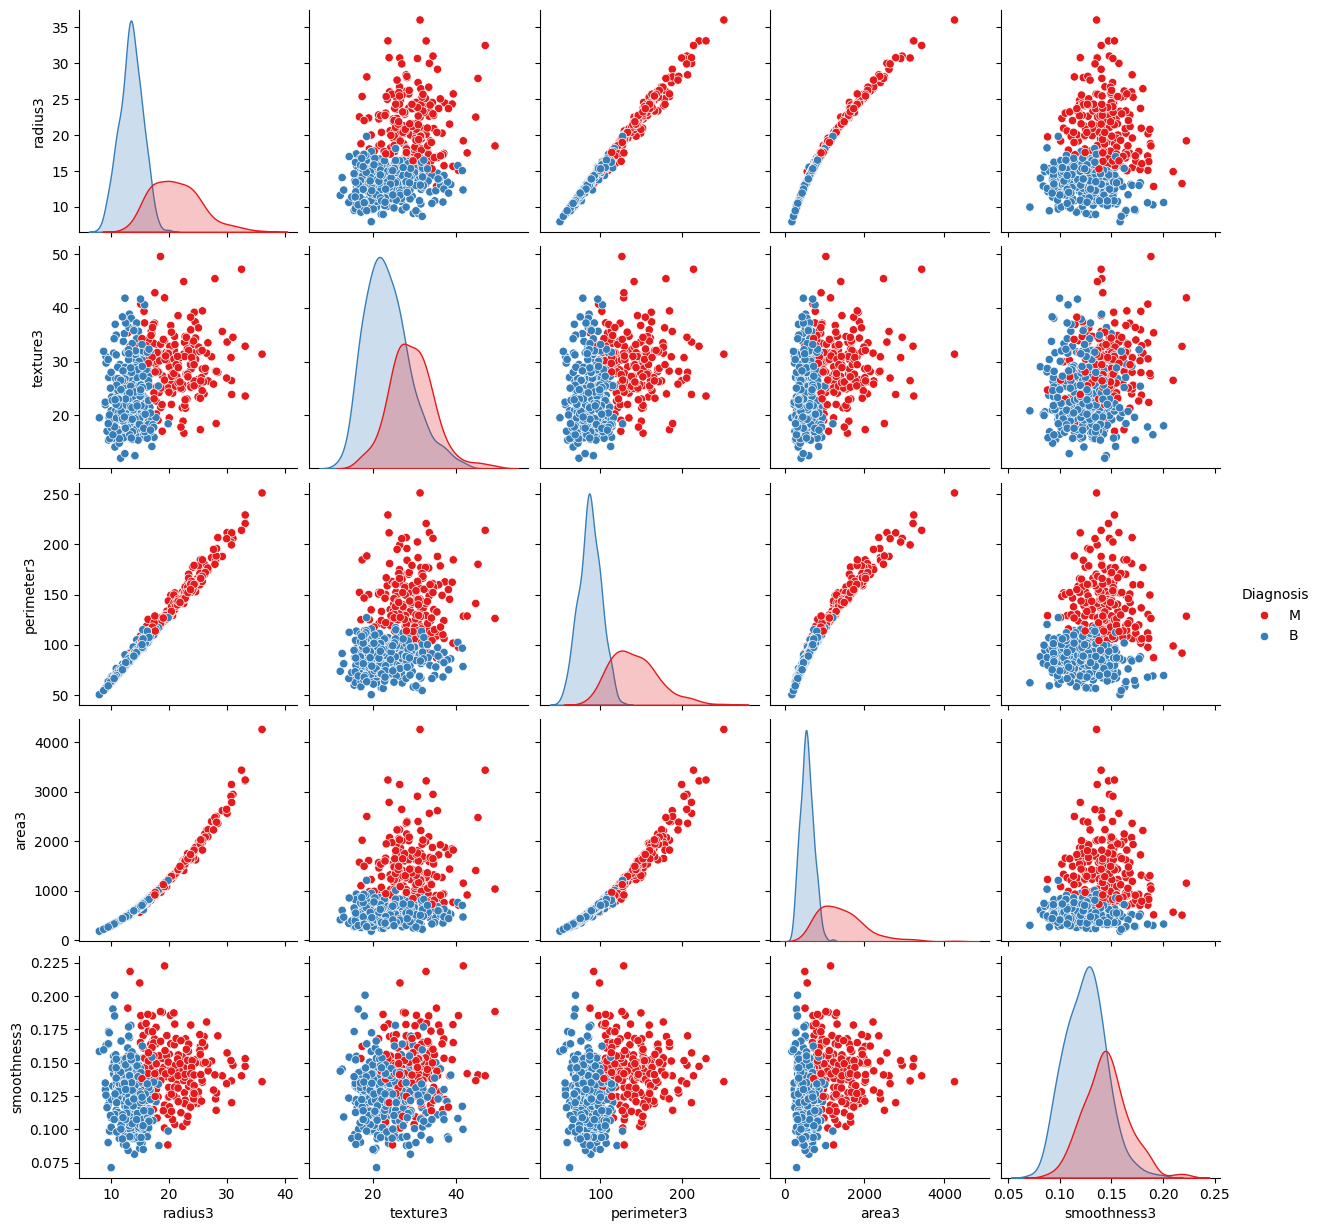

In [ ]:
# Group 3: Worst measurements

worst_features = [
    "radius3",
    "texture3",
    "perimeter3",
    "area3",
    "smoothness3",
    "Diagnosis"
]

sns.pairplot(
    df[worst_features],
    hue="Diagnosis",
    diag_kind="kde",
    palette="Set1"
)

plt.show()